In [1]:
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display

from cognitive_maps_in_llms.analysis import (
    RunResults,
    compute_pca_projection,
    plot_pca_activity_space,
)

In [2]:
REPO_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / 'src' / 'cognitive_maps_in_llms').is_dir()
)

# SET INPUT AND OUTPUT PATHS

# ------------------------------------------------------------------------------
RESULTS_ROOT = REPO_ROOT / 'results/final_run_2026-09-30'
FIGURES_DIR  = REPO_ROOT / 'figures/generated/supplementary/figure_s4'
SAVE_FIGURES = True
# ------------------------------------------------------------------------------

if SAVE_FIGURES:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# The full set of recorded activations for all models and tasks is too large
# to be included in the `results` folder. However, we have included a copy
# of the llama-70b activations in the "family-tree" setting, sufficient for generating
# the figure in the SI
RESULTS = RunResults(artifacts_root=RESULTS_ROOT)


In [3]:
# LOAD RECORDINGS

MODEL_PRESET = 'llama-70b'
PROMPT_PRESET = 'ABC_family_tree_yes_no'

recordings = RESULTS.load_activation_recordings(
    model_preset=MODEL_PRESET,
    prompt_preset=PROMPT_PRESET,
    task="pca_inputs",
)
print('Activation shape (graph, seed, token, layer, feature):', recordings.Z_gstla.shape)
print('Landmarks: ' + str(recordings.context_landmarks))

Activation shape (graph, seed, token, layer, feature): (4, 100, 2, 80, 8192)
Landmarks: {'R_BC': 0, 'C1': 1}


In [4]:
# COMPUTE PCA AXES AND PROJECT

TOKENS = ('R_BC', 'C1')
REFERENCE_LAYER = 40
N_COMPONENTS = 3

projections = {
    token: compute_pca_projection(
        recordings,
        average_over_seeds=False,
        token=token,
        reference_layer=REFERENCE_LAYER,
        n_components=N_COMPONENTS
    )
    for token in TOKENS
}

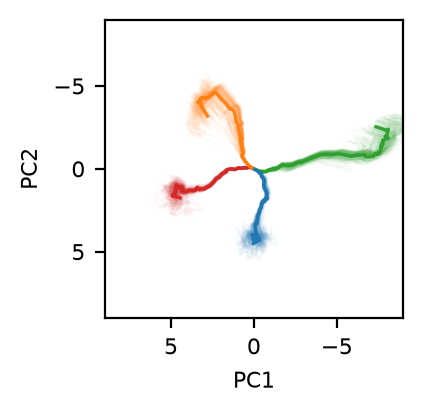

In [5]:
# PLOT PROJECTION ONTO THE FIRST 2 PCS AT THE SECOND RELATION TOKEN

plot = plot_pca_activity_space(projections['R_BC'])
plot.ax.set_xlim((9, -9))
plot.ax.set_ylim((9, -9))
display(plot.fig)
if SAVE_FIGURES:
    plot.save(FIGURES_DIR / 'R_BC_PCA.svg')
plt.close(plot.fig)

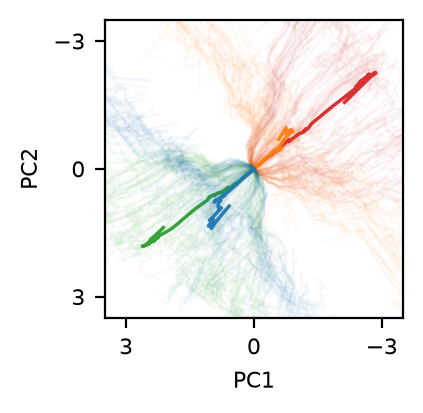

In [6]:
# PLOT PROJECTION ONTO THE FIRST 2 PCS AT THE THIRD ENTITY TOKEN

plot = plot_pca_activity_space(projections['C1'])
plot.ax.set_xlim((3.5, -3.5))
plot.ax.set_xticks((-3, 0, 3))
plot.ax.set_ylim((3.5, -3.5))
plot.ax.set_yticks((-3, 0, 3))
display(plot.fig)
if SAVE_FIGURES:
    plot.save(FIGURES_DIR / 'C1_PCA.svg')
plt.close(plot.fig)

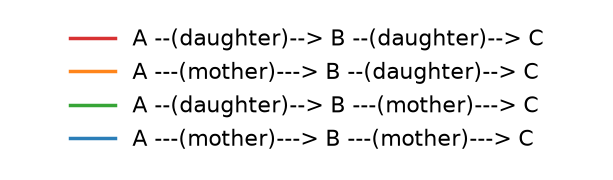

In [7]:
# RENDER LEGEND

from cognitive_maps_in_llms.analysis.style import PAPER_MOSAIC_STYLE

labels = (
    "A --(daughter)--> B --(daughter)--> C",
    "A ---(mother)---> B --(daughter)--> C",
    "A --(daughter)--> B ---(mother)---> C",
    "A ---(mother)---> B ---(mother)---> C",
)
handles = plot.artists["mean_trajectories"]

with plt.rc_context(PAPER_MOSAIC_STYLE.rc_params()):
    fig, ax = plt.subplots(figsize=(3.7, 0.85))
    ax.set_axis_off()
    ax.legend(handles, labels, loc="center", frameon=False)
    display(fig)
    if SAVE_FIGURES:
        fig.savefig(FIGURES_DIR / "pca_family_tree_legend.svg", bbox_inches="tight")
    plt.close(fig)